# 04 — Treinamento, Otimização e Avaliação dos Modelos (versão 3)

**Objetivo.** Estimar $f(\mathbf{X}_{i,T})$ para a variação do valor de mercado em $T+1$ e $T+2$,
comparar algoritmos e arquiteturas e testar formalmente as hipóteses do estudo:
- **H1:** o desempenho em $T$ tem poder preditivo além do que o Transfermarkt (nível e trajetória do
  valor) e a idade já contêm;
- **H2:** a matriz 4 × 3 supera a 3 × 3 de Khalife et al. (2025) e o modelo global.

**Entrada:** `data/processed/train_test_lags.parquet` e `feature_sets.json` (notebook 03).
**Saídas:**
- modelos finais em `models/04_model_training/final/`, com manifesto;
- previsões fora da amostra em `data/processed/predictions_oof.parquet` e `predictions_best.parquet`,
  inclusive para os atletas que saíram da base (sem $V_{T+k}$);
- protocolo pré-registrado em `reports/protocol_v3.json`;
- tabelas e figuras em `reports/`.

### O que muda em relação à versão 2

| Tema | Versão 2 | Versão 3 |
|---|---|---|
| Amostra | 2019/20–2023/24 | 2018/19–2024/25 (+ 2017/18 só para defasagens) |
| Teste final de $T+1$ | 2023/24, consultado no desenvolvimento | **2024/25, pré-registrado**: revelado só depois do commit do protocolo |
| Hiperparâmetros | 15 avaliações em 4 a 8 dimensões; ótimos na fronteira | taxa de aprendizado fixa, árvores por parada antecipada temporal, espaços centrados em regularização, 20 avaliações em 3 a 5 dimensões |
| Inferência | *bootstrap* iid por atleta, só contra o CatBoost | *bootstrap* por clube × temporada, teste pareado de perdas com correção de Holm e MCS |
| Segmentação | 12 modelos, vencedor por categoria | 4 × 3 contra 3 × 3 de Khalife, com algoritmo fixo e *pooling* parcial |
| Ablação | — | por blocos de variáveis (H1) |

## Desenho experimental

| Elemento | Definição |
|---|---|
| Alvo de treino | log-retorno $y = \ln(V_{T+k}/V_T)$, reconvertido para $\Delta V\%$ e $\Delta V$ (€) |
| Validação | janela expandida: 6 dobras em $T+1$ (teste de 2019/20 a 2024/25) e 4 em $T+2$, com purga de uma temporada (teste de 2020/21 a 2023/24) |
| Teste final | $T+1$: **2024/25**, pré-registrado. $T+2$: 2023/24, semi-independente (consultado nas versões 1 e 2). Nenhum dos dois participa da otimização ou da escolha de modelos |
| Otimização | bayesiana com processo gaussiano (`skopt.gp_minimize`), RMSE média das **3 últimas dobras de validação**: 20 avaliações (10 aleatórias) no modelo global e 10 nos segmentos |
| Parada antecipada | XGBoost e CatBoost com taxa de aprendizado 0,05; a última temporada do treino (com purga em $T+2$) escolhe o número de árvores (paciência de 40, até 1.000), e o modelo é reajustado em todo o treino |
| Pré-processamento na dobra | mediana do treino por posição; nos lineares, winsorização p1/p99 e escalonamento robusto |
| Modelos globais | mediana do treino, OLS (vetor compacto), Ridge, Random Forest, XGBoost, CatBoost e o *ensemble* (média simples de CatBoost, XGBoost e Ridge, fixada a priori) |
| Segmentos | mediana, Ridge e CatBoost por categoria, nas matrizes 4 × 3 (C1–C12) e 3 × 3 (K1–K9) |
| Métricas | RMSE, MAE e $R^2$ nas três escalas; $\rho$ de Spearman; acerto do decil superior; inclinação de calibração; cobertura dos intervalos |
| Inferência | ICs por *bootstrap* de clusters (clube × temporada); teste pareado tipo Diebold–Mariano com erro-padrão por cluster e correção de Holm; MCS de Hansen, Lunde e Nason (2011) |

## 0. Configuração

In [1]:
import hashlib
import json
import os
import subprocess
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from joblib import Parallel, delayed, parallel_config

from football_analytics import feature_catalog as fc
from football_analytics import modeling as md
from football_analytics import plotting as pl
from football_analytics import sample as sp
from football_analytics.config import default_config
from football_analytics.io import load_table, save_table
from football_analytics.logging_utils import setup_logging
from football_analytics.validation import Fold

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# FA_SMOKE_TEST=1: 15% das linhas e poucas avaliações, com saídas em data/smoke_test/04/
SMOKE_TEST = os.environ.get("FA_SMOKE_TEST") == "1"
# O teste final de T+1 (2024/25) só é revelado depois do commit do protocolo (seção 5):
# FA_REVEAL_HOLDOUT=1 na segunda execução. O cache torna a reexecução rápida.
REVEAL_HOLDOUT = SMOKE_TEST or os.environ.get("FA_REVEAL_HOLDOUT") == "1"
cfg = default_config()
paths = cfg.paths
logger = setup_logging(paths.logs / "04_model_training.log")
pl.setup_style()
OUT = paths.root / "data" / "smoke_test" / "04" if SMOKE_TEST else None
FIG = pl.FigureRegistry(OUT / "figures" if SMOKE_TEST else paths.figures("04_model_training"),
                        source="Elaboração própria com dados de FBref, Understat, Sofascore e Transfermarkt (2026)")
TABLES = OUT / "tables" if SMOKE_TEST else paths.tables("04_model_training")
TABLES.mkdir(parents=True, exist_ok=True)
MODELS_DIR = OUT / "models" if SMOKE_TEST else paths.root / "models" / "04_model_training"
PROCESSED_OUT = OUT if SMOKE_TEST else paths.processed
CACHE = MODELS_DIR / "cache"
FINAL = MODELS_DIR / "final"
PROTOCOL_PATH = (OUT if SMOKE_TEST else paths.reports) / "protocol_v3.json"


def save_csv(df: pd.DataFrame, name: str, index: bool = True) -> None:
    df.to_csv(TABLES / f"{name}.csv", index=index, encoding="utf-8-sig", float_format="%.5f")


N_JOBS = 8
N_CALLS = {"global": 6, "ridge": 6, "segment": 5} if SMOKE_TEST else {"global": 20, "ridge": 15, "segment": 10}
SPECS = {"global": md.model_specs(N_CALLS["global"], N_CALLS["ridge"]),
         "segment": md.model_specs(N_CALLS["segment"], N_CALLS["segment"])}
MODELS = ["median", "ols", "ridge", "rf", "xgb", "cat"]
SEG_MODELS = ["median", "ridge", "cat"]
ENSEMBLE = ["cat", "xgb", "ridge"]           # fixado a priori (versão 2), sem pesos ajustados
MODEL_LABELS = {k: SPECS["global"][k].label for k in MODELS}
LABELS = {**MODEL_LABELS, "zero": "Sem variação", "ens": "Ensemble (CatBoost + XGBoost + Ridge)", "pool": "Pooling parcial"}
SEGMENTATIONS = {
    "4x3": ("category", [f"C{i}" for i in range(1, 13)], sp.category_labels()),
    "3x3": ("category_3x3", [f"K{i}" for i in range(1, 10)], sp.category_labels(sp.AGE_BAND_3X3_LABELS, "K")),
}
SEG_NAME = {"category": "4 × 3", "category_3x3": "3 × 3"}
CAT_GLOBAL = ("league", "age_band", "position_group")
CAT_SEGMENT = ("league",)
HORIZONS = (1, 2)

In [2]:
panel_path = paths.processed / "train_test_lags.parquet"
panel = load_table(panel_path)
if SMOKE_TEST:
    panel = panel.groupby(["season", "category"], group_keys=False).sample(frac=0.15, random_state=0)
# o hash do painel entra na chave do cache: dados novos nunca reaproveitam resultados antigos
DATA_TAG = hashlib.md5(panel_path.read_bytes()).hexdigest()[:10] + ("-smoke" if SMOKE_TEST else "")
fs = json.loads((paths.processed / "feature_sets.json").read_text(encoding="utf-8"))
NUMERIC = tuple(fs["numeric_features"])
LOOKAHEAD = tuple(fs["lookahead_features"])
RAW_TWINS = fs["raw_twins"]
folds = {k: [Fold(tuple(f["train"]), f["test"], tuple(f["purged"])) for f in fs["folds"][f"T{k}"]] for k in HORIZONS}
TUNING = {k: fl[:-1][-3:] for k, fl in folds.items()}      # as 3 últimas dobras de validação
N_FOLDS = {k: len(fl) for k, fl in folds.items()}
HOLDOUT = {k: fl[-1].test for k, fl in folds.items()}
FIRST_CAL = md.BURN_IN_FOLDS + 2   # 1ª dobra com histórico nas camadas de magnitude e conformal
assert HOLDOUT == {k: cfg.holdout_seasons[k] for k in HORIZONS}, HOLDOUT
print(f"Painel: {len(panel):,} linhas | {len(NUMERIC)} features | hash {DATA_TAG} | "
      f"fora do vetor: {fs.get('excluded_features') or 'nenhuma'}")
for k, fl in folds.items():
    print(f"  T+{k}: {len(fl)} dobras | otimização em " + ", ".join(sp.season_label(f.test) for f in TUNING[k])
          + f" | teste final {sp.season_label(HOLDOUT[k])}")
print("Teste final de T+1 REVELADO" if REVEAL_HOLDOUT else "Teste final de T+1 OCULTO (antes do protocolo)")

# Blocos de variáveis para a ablação (H1), a partir dos grupos do catálogo
groups = fs["feature_groups"]
PERF_GROUPS = ["Volume", "Ofensivo", "Criação e posse", "Defensivo", "Disciplina", "Avaliação agregada"]
TM_TRAJECTORY = ["log_return_lag1", "log_return_lag2"]
BLOCKS = {
    "Demografia e idade": groups.get("Demográfico", []),
    "Contrato (T-safe)": groups.get("Contratual", []),
    "Nível de preço (TM)": groups.get("Mercado", []),
    "Contexto do clube": groups.get("Contexto", []),
    "Trajetória do valor (TM)": groups.get("Dinâmica de mercado", []) + TM_TRAJECTORY,
    "Desempenho em T": [c for g in PERF_GROUPS for c in groups.get(g, [])],
    "Desempenho em T−1": [c for c in groups.get("Defasagem", []) if c not in TM_TRAJECTORY],
    "Valor justo e gap": groups.get("Valor justo", []),
}
BLOCKS = {name: cols for name, cols in BLOCKS.items() if cols}   # blocos sem variáveis (fora por cobertura) saem
assert sorted(c for v in BLOCKS.values() for c in v) == sorted(NUMERIC), "blocos não cobrem o vetor"
print("Blocos da ablação:", {n: len(v) for n, v in BLOCKS.items()})


def combo(*names: str) -> tuple[str, ...]:
    keep = {c for n in names if n in BLOCKS for c in BLOCKS[n]}
    return tuple(c for c in NUMERIC if c in keep)


ALL_BLOCKS = list(BLOCKS)
CAT_NO_AGE = ("league", "position_group")
ABLATIONS = {  # nome: (numéricas, categóricas)
    **{f"Sem {n.lower()}": (combo(*[b for b in ALL_BLOCKS if b != n]),
                            CAT_NO_AGE if n == "Demografia e idade" else CAT_GLOBAL) for n in ALL_BLOCKS},
    "Sem desempenho (T, T−1) e valor justo": (combo("Demografia e idade", "Contrato (T-safe)", "Nível de preço (TM)",
                                                    "Contexto do clube", "Trajetória do valor (TM)"), CAT_GLOBAL),
    "M0: ciclo de vida + contexto": (combo("Demografia e idade", "Contrato (T-safe)", "Contexto do clube"), CAT_GLOBAL),
    "M1: M0 + nível de preço": (combo("Demografia e idade", "Contrato (T-safe)", "Contexto do clube",
                                      "Nível de preço (TM)"), CAT_GLOBAL),
    "M2: M1 + trajetória do valor": (combo("Demografia e idade", "Contrato (T-safe)", "Contexto do clube",
                                           "Nível de preço (TM)", "Trajetória do valor (TM)"), CAT_GLOBAL),
    "Fiel às specs: M1 + desempenho + valor justo": (combo("Demografia e idade", "Contrato (T-safe)", "Contexto do clube",
                                                           "Nível de preço (TM)", "Desempenho em T", "Desempenho em T−1",
                                                           "Valor justo e gap"), CAT_GLOBAL),
}
ABL_SLUG = {name: f"abl{i:02d}" for i, name in enumerate(ABLATIONS)}
pd.DataFrame({"variaveis": {n: len(v[0]) for n, v in ABLATIONS.items()}})

Painel: 13,748 linhas | 108 features | hash 667144f5f2 | fora do vetor: {'club_elo_T': 'cobertura mínima por temporada de 0% (< 90%)', 'club_elo_change_T': 'cobertura mínima por temporada de 0% (< 90%)', 'tenure_years_T': 'cobertura mínima por temporada de 80% (< 90%)', 'is_on_loan_T': 'cobertura mínima por temporada de 80% (< 90%)'}
  T+1: 6 dobras | otimização em 2021/22, 2022/23, 2023/24 | teste final 2024/25
  T+2: 4 dobras | otimização em 2020/21, 2021/22, 2022/23 | teste final 2023/24
Teste final de T+1 OCULTO (antes do protocolo)
Blocos da ablação: {'Demografia e idade': 12, 'Nível de preço (TM)': 5, 'Contexto do clube': 8, 'Trajetória do valor (TM)': 10, 'Desempenho em T': 58, 'Desempenho em T−1': 13, 'Valor justo e gap': 2}


,variaveis
Sem demografia e idade,96
Sem nível de preço (tm),103
Sem contexto do clube,100
Sem trajetória do valor (tm),98
Sem desempenho em t,50
Sem desempenho em t−1,95
Sem valor justo e gap,106
"Sem desempenho (T, T−1) e valor justo",35
M0: ciclo de vida + contexto,20
M1: M0 + nível de preço,25


## 1. Custo computacional

Antes da grade, mede-se o custo de um ajuste com os hiperparâmetros-padrão no maior treino das
dobras de otimização. O processador é um i5-10300H em modo de economia; a meta é uma execução a
frio de até cerca de 2,5 horas, com cache por tarefa.

In [3]:
probe = folds[1][:-1][-1]           # última dobra de validação de T+1: o maior treino da otimização
d1 = panel[panel["has_target_T1"] == 1]
probe_train = d1[d1["season"].isin(probe.train)]
fit_seconds = {}
for m in ("ridge", "xgb", "cat", "rf"):
    t0 = time.time()
    md.build_model(SPECS["global"][m], md.DEFAULT_PARAMS[m], md.Task(1, "global", m, NUMERIC, CAT_GLOBAL)).fit(
        probe_train, probe_train["log_return_T1"].to_numpy())
    fit_seconds[m] = time.time() - t0
cost = pd.Series(fit_seconds, name="segundos por ajuste").to_frame()
# projeção grosseira: avaliações × 3 dobras de otimização + avaliação em todas as dobras, nos dois horizontes
n_fits = {m: 2 * (SPECS["global"][m].n_calls * 3 + N_FOLDS[1]) for m in fit_seconds}
cost["ajustes no modelo global"] = pd.Series(n_fits)
cost["CPU-min (global)"] = cost["segundos por ajuste"] * cost["ajustes no modelo global"] / 60 * 0.7
print(f"Treino da sonda: {len(probe_train):,} linhas")
cost.round(1)

Treino da sonda: 9,605 linhas


,segundos por ajuste,ajustes no modelo global,CPU-min (global)
ridge,1.2000,102,1.5000
xgb,4.9000,132,7.5000
cat,6.9000,132,10.7000
rf,28.5000,132,44.0000


## 2. Execução das tarefas

Cada tarefa (horizonte × escopo × algoritmo) otimiza os hiperparâmetros nas 3 últimas dobras de
validação, avalia em todas as dobras com os hiperparâmetros escolhidos e grava o resultado em cache.
As tarefas de robustez e de ablação reaproveitam os hiperparâmetros do modelo principal
(`fixed_params`), para isolar o efeito do que muda.

In [4]:
def execute(task: md.Task, fixed: dict | None = None, data: pd.DataFrame | None = None) -> dict:
    specs = SPECS["global" if task.scope == "global" else "segment"]
    return md.run_task(task, panel if data is None else data, folds[task.horizon], TUNING[task.horizon], specs,
                       CACHE, fixed_params=fixed)


def T(k: int, scope: str, model: str, numeric=NUMERIC, categorical=None, extra: str = "",
      scope_col: str = "category") -> md.Task:
    categorical = categorical if categorical is not None else (CAT_GLOBAL if scope == "global" else CAT_SEGMENT)
    return md.Task(k, scope, model, tuple(numeric), tuple(categorical), extra, scope_col, DATA_TAG)


tasks = [T(k, "global", m) for k in HORIZONS for m in MODELS]
for col, scopes, _ in SEGMENTATIONS.values():
    tasks += [T(k, c, m, scope_col=col) for k in HORIZONS for m in SEG_MODELS for c in scopes]
weight = {"rf": 6.0, "cat": 3.0, "xgb": 2.0, "ridge": 0.1, "ols": 0.05, "median": 0.01}
size = {**panel["category"].value_counts().to_dict(), **panel["category_3x3"].value_counts().to_dict()}
order = sorted(tasks, key=lambda t: -weight[t.model] * (len(panel) if t.scope == "global" else size.get(t.scope, 1)))
cached = sum((CACHE / f"{t.key()}.joblib").exists() for t in tasks)
print(f"{len(tasks)} tarefas otimizadas; {cached} já em cache")
t0 = time.time()
with parallel_config(backend="loky", inner_max_num_threads=1):
    results = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(execute)(t) for t in order)
print(f"concluído em {(time.time() - t0) / 60:,.1f} min")
by_key = {(r["task"].horizon, r["task"].scope, r["task"].model): r for r in results}

138 tarefas otimizadas; 138 já em cache


concluído em 0.2 min


In [5]:
def P(k: int, m: str) -> dict:
    return by_key[(k, "global", m)]["params"]


no_pandemic = panel[panel["season"] != "1819"]   # sem as janelas de alvo que cruzam a revisão de abril/2020
fixed_jobs = []
for k in HORIZONS:
    fixed_jobs.append((T(k, "global", "xgb", NUMERIC + LOOKAHEAD, extra="lookahead"), P(k, "xgb"), None))
    for q in (0.1, 0.9):
        fixed_jobs.append((T(k, "global", "cat", extra=f"q{int(q * 100)}"), P(k, "cat") | {"loss_function": f"Quantile:alpha={q}"},
                           None))
    for m in ENSEMBLE:
        fixed_jobs.append((T(k, "global", m, extra="padrao"), md.DEFAULT_PARAMS[m], None))
        fixed_jobs.append((T(k, "global", m, [RAW_TWINS.get(c, c) for c in NUMERIC], extra="cru"), P(k, m), None))
        fixed_jobs.append((T(k, "global", m, extra="sem_pandemia"), P(k, m), no_pandemic))
        for name, (num, cat) in ABLATIONS.items():
            fixed_jobs.append((T(k, "global", m, num, cat, extra=ABL_SLUG[name]), P(k, m), None))
cached = sum((CACHE / f"{t.key()}.joblib").exists() for t, _, _ in fixed_jobs)
print(f"{len(fixed_jobs)} tarefas com hiperparâmetros fixos; {cached} já em cache")
t0 = time.time()
with parallel_config(backend="loky", inner_max_num_threads=1):
    fixed_results = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(execute)(t, f, d) for t, f, d in fixed_jobs)
print(f"concluído em {(time.time() - t0) / 60:,.1f} min")

timing = (pd.DataFrame([{"horizonte": f"T+{r['task'].horizon}",
                         "escopo": "Global" if r["task"].scope == "global" else SEG_NAME[r["task"].scope_col],
                         "tipo": "fixo" if r["task"].extra_label else "otimizado",
                         "modelo": MODEL_LABELS[r["task"].model], "segundos": r["seconds"]} for r in results + fixed_results])
          .groupby(["horizonte", "escopo", "tipo", "modelo"])["segundos"].sum().unstack("horizonte").div(60))
save_csv(timing, "tab01_tempo_computacional_min")
print(f"Tempo total de CPU: {timing.sum().sum():,.0f} min")
timing.round(1)

96 tarefas com hiperparâmetros fixos; 96 já em cache


concluído em 0.0 min
Tempo total de CPU: 440 min


horizonte                                        T+1     T+2
escopo tipo      modelo                                     
3 × 3  otimizado CatBoost                    58.6000 40.9000
                 Mediana do treino (ingênuo)  0.0000  0.0000
                 Ridge                       12.3000 11.4000
4 × 3  otimizado CatBoost                    68.5000 53.8000
                 Mediana do treino (ingênuo)  0.0000  0.0000
                 Ridge                       15.9000 14.6000
Global fixo      CatBoost                    10.0000  5.0000
                 Ridge                        3.1000  1.8000
                 XGBoost                      9.4000  3.8000
       otimizado CatBoost                    18.9000  9.8000
                 Mediana do treino (ingênuo)  0.0000  0.0000
                 OLS                          0.1000  0.0000
                 Random Forest               56.5000 26.1000
                 Ridge                        2.4000  2.2000
                 XGBoost                      9.7000  4.9000

## 3. Hiperparâmetros otimizados e convergência

Com a taxa de aprendizado fixa e o número de árvores escolhido por parada antecipada, a busca cobre
só complexidade e regularização: 5 dimensões no XGBoost, 3 no CatBoost e na Random Forest. A tabela
indica, para cada hiperparâmetro, se o ótimo caiu na fronteira do espaço, o sintoma que motivou a
revisão dos espaços da versão 2.

,horizonte,modelo,hiperparametro,valor,na_fronteira
0,T+1,Random Forest,max_depth,18,False
1,T+1,Random Forest,min_samples_leaf,1,True
2,T+1,Random Forest,max_features,0.2,False
3,T+2,Random Forest,max_depth,25,True
4,T+2,Random Forest,min_samples_leaf,6,False
5,T+2,Random Forest,max_features,0.2,False
6,T+1,CatBoost,depth,3,True
7,T+1,CatBoost,l2_leaf_reg,12.2675,False
8,T+1,CatBoost,random_strength,0.0187,False
9,T+2,CatBoost,depth,4,False


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig01_convergencia_otimizacao.png


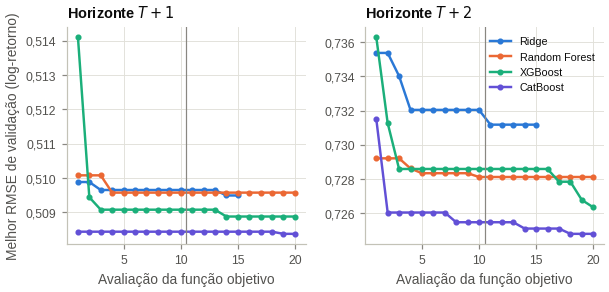

In [6]:
hp_rows = []
for r in results:
    t = r["task"]
    if t.scope != "global" or not r["params"]:
        continue
    spec = SPECS["global"][t.model]
    for name, dim in zip(spec.param_names, spec.space):
        v = r["params"][name]
        lo, hi = (dim.bounds if hasattr(dim, "bounds") and not isinstance(dim.bounds[0], str) else (None, None))
        hp_rows.append({"horizonte": f"T+{t.horizon}", "modelo": MODEL_LABELS[t.model], "hiperparametro": name, "valor": v,
                        "na_fronteira": bool(lo is not None and isinstance(v, (int, float)) and (np.isclose(v, lo) or np.isclose(v, hi)))})
hp = pd.DataFrame(hp_rows)
save_csv(hp, "tab02_hiperparametros_globais", index=False)
display(hp)

seg_hp = pd.DataFrame([{"horizonte": f"T+{r['task'].horizon}", "matriz": SEG_NAME[r["task"].scope_col],
                        "segmento": r["task"].scope, "modelo": MODEL_LABELS[r["task"].model], "params": json.dumps(r["params"])}
                       for r in results if r["task"].scope != "global" and r["params"]])
save_csv(seg_hp, "tab03_hiperparametros_segmentados", index=False)

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), sharey=False, gridspec_kw={"wspace": 0.25})
colors = {"ridge": pl.BLUE, "rf": pl.ORANGE, "xgb": pl.AQUA, "cat": "#6250d6"}
for ax, k in zip(axes, HORIZONS):
    for m, color in colors.items():
        hist = by_key[(k, "global", m)]["history"]
        ax.plot(range(1, len(hist) + 1), np.minimum.accumulate(hist), color=color, marker="o", markersize=3,
                linewidth=1.6, label=MODEL_LABELS[m])
    ax.axvline(min(10, N_CALLS["global"] // 2) + 0.5, color=pl.INK_MUTED, linewidth=0.8)
    ax.set_title(f"Horizonte $T+{k}$")
    ax.set_xlabel("Avaliação da função objetivo")
    ax.yaxis.set_major_formatter(pl.br_formatter(3))
axes[0].set_ylabel("Melhor RMSE de validação (log-retorno)")
axes[1].legend(loc="upper right", fontsize=7)
FIG.save(fig, "fig01_convergencia_otimizacao",
         "Convergência da otimização bayesiana dos hiperparâmetros dos modelos globais",
         note="À esquerda da linha vertical, pontos iniciais aleatórios; à direita, pontos escolhidos pelo processo gaussiano. "
              "RMSE média das três últimas dobras de validação.")
plt.show()

## 4. Previsões fora da amostra e decisões nas dobras de desenvolvimento

As previsões dos segmentos são unidas para formar cada arquitetura segmentada. O ***pooling* parcial**
combina, em cada categoria, a previsão do CatBoost do segmento com a do *ensemble* global:
$\hat y = w_c\,\hat y_{\text{seg}} + (1-w_c)\,\hat y_{\text{global}}$, com $w_c = n_c/(n_c+\kappa)$ e $n_c$ o
treino da categoria na dobra. É um encolhimento da previsão do segmento para a do modelo global,
tanto mais forte quanto menor o segmento, e $\kappa$ é escolhido nas dobras de validação.

Todas as decisões desta seção usam **apenas as dobras de desenvolvimento** (todas menos o teste final
de cada horizonte).

In [7]:
preds = []
for r in results + fixed_results:
    t = r["task"]
    preds.append(r["predictions"].assign(horizon=t.horizon, scope=t.scope, scope_col=t.scope_col, model=t.model,
                                         extra=t.extra_label))
pred = pd.concat(preds, ignore_index=True)
pred["approach"] = np.where(pred["scope"] == "global", "Global", "Seg. " + pred["scope_col"].map(SEG_NAME))
pred["dev"] = pred["fold"] < pred["horizon"].map(N_FOLDS)
KEY = ["horizon", "season", "fbref_player_id"]


def ensemble(frame: pd.DataFrame, members: list[str] = ENSEMBLE, name: str = "ens") -> pd.DataFrame:
    """Média simples das previsões dos membros, para as mesmas linhas."""
    sub = frame[frame["model"].isin(members)]
    avg = sub.groupby(KEY, as_index=False).agg(y_pred=("y_pred", "mean"), n=("model", "size"))
    avg = avg[avg["n"] == len(members)].drop(columns="n")
    return frame[frame["model"] == members[0]].drop(columns="y_pred").merge(avg, on=KEY).assign(model=name)


main = pred[pred["extra"] == ""]
zero = main[(main["approach"] == "Global") & (main["model"] == "median")].assign(model="zero", y_pred=0.0)
ens = ensemble(main[main["approach"] == "Global"])
variants = {extra: ensemble(pred[(pred["extra"] == extra) & (pred["scope"] == "global")]).assign(extra=extra)
            for extra in ["padrao", "cru", "sem_pandemia", *ABL_SLUG.values()]}

# treino de cada categoria em cada dobra (para o pooling)
ntr_rows = []
for k in HORIZONS:
    for i, f in enumerate(folds[k], 1):
        tr = panel[panel["season"].isin(f.train) & (panel[f"has_target_T{k}"] == 1)]
        for col, scopes, _ in SEGMENTATIONS.values():
            counts = tr[col].value_counts()
            ntr_rows += [{"horizon": k, "fold": i, "scope_col": col, "scope": s, "n_train": int(counts.get(s, 0))} for s in scopes]
ntr = pd.DataFrame(ntr_rows)


def pooled(col: str, kappa: float) -> pd.DataFrame:
    seg = main[(main["scope_col"] == col) & (main["scope"] != "global") & (main["model"] == "cat")]
    g = ens[["horizon", "season", "fbref_player_id", "y_pred"]].rename(columns={"y_pred": "y_global"})
    m = seg.merge(g, on=KEY).merge(ntr[ntr["scope_col"] == col], on=["horizon", "fold", "scope_col", "scope"])
    m["y_pred"] = md.pool_predictions(m["y_global"], m["y_pred"], m["n_train"], kappa)
    return m.drop(columns=["y_global", "n_train"]).assign(model="pool", approach=f"Pooling {SEG_NAME[col]}")


def fold_rmse(frame: pd.DataFrame) -> pd.Series:
    """RMSE média das dobras de validação por horizonte (o mesmo critério da otimização)."""
    v = frame[frame["dev"] & frame["y_true"].notna()]
    return v.groupby(["horizon", "fold"]).apply(lambda d: md.rmse(d["y_true"], d["y_pred"])).groupby("horizon").mean()


KAPPAS = [0, 25, 50, 100, 200, 400, 800, 1600, 3200, 6400, np.inf]
kappa_grid = pd.DataFrame({(SEG_NAME[col], kappa): fold_rmse(pooled(col, kappa)) for col, _, _ in SEGMENTATIONS.values()
                           for kappa in KAPPAS}).T
kappa_grid.index.names = ["matriz", "kappa"]
best_kappa = {(col, k): float(kappa_grid.loc[SEG_NAME[col]][k].idxmin()) for col, _, _ in SEGMENTATIONS.values() for k in HORIZONS}
pools = []
for col, _, _ in SEGMENTATIONS.values():
    for k in HORIZONS:
        p_ = pooled(col, best_kappa[(col, k)])
        pools.append(p_[p_["horizon"] == k])
pools = pd.concat(pools, ignore_index=True)
main = pd.concat([main, zero, ens, pools], ignore_index=True)
save_csv(kappa_grid, "tab04a_pooling_kappa_validacao")
print("κ escolhido nas dobras de validação:", {f"{SEG_NAME[c]} T+{k}": v for (c, k), v in best_kappa.items()})
kappa_grid.round(4)

κ escolhido nas dobras de validação: {'4 × 3 T+1': 3200.0, '4 × 3 T+2': 800.0, '3 × 3 T+1': 3200.0, '3 × 3 T+2': 800.0}


horizon                1      2
matriz kappa                   
4 × 3  0.0000     0.5281 0.7315
       25.0000    0.5265 0.7288
       50.0000    0.5254 0.7271
       100.0000   0.5238 0.7248
       200.0000   0.5219 0.7226
       400.0000   0.5201 0.7211
       800.0000   0.5188 0.7206
       1,600.0000 0.5182 0.7208
       3,200.0000 0.5180 0.7212
       6,400.0000 0.5181 0.7216
       inf        0.5183 0.7222
3 × 3  0.0000     0.5281 0.7308
       25.0000    0.5269 0.7284
       50.0000    0.5259 0.7268
       100.0000   0.5244 0.7246
       200.0000   0.5225 0.7223
       400.0000   0.5206 0.7206
       800.0000   0.5191 0.7200
       1,600.0000 0.5183 0.7203
       3,200.0000 0.5181 0.7209
       6,400.0000 0.5181 0.7214
       inf        0.5183 0.7222

In [8]:
def metrics_by(df: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    return df.groupby(by).apply(md.regression_metrics).reset_index()


per_fold = metrics_by(main, ["horizon", "approach", "model", "fold"])
per_fold["dev"] = per_fold["fold"] < per_fold["horizon"].map(N_FOLDS)
validation = (per_fold[per_fold["dev"]].groupby(["horizon", "approach", "model"])
              [["RMSE_log", "R2_log", "spearman", "top10_hit_rate"]].mean().add_suffix("_validacao").reset_index())
cols = ["RMSE_log_validacao", "R2_log_validacao", "spearman_validacao", "top10_hit_rate_validacao"]
val_tab = validation.assign(modelo=validation["model"].map(LABELS), horizonte="T+" + validation["horizon"].astype(str))
val_tab = val_tab.set_index(["horizonte", "approach", "modelo"])[cols].sort_index()
save_csv(val_tab, "tab04_metricas_validacao")
val_tab.round(4)

RMSE_log_validacao  R2_log_validacao  spearman_validacao  top10_hit_rate_validacao
horizonte approach      modelo                                                                                                                   
T+1       Global        CatBoost                                           0.5211            0.2325              0.5005                    0.6115
                        Ensemble (CatBoost + XGBoost + Ridge)              0.5183            0.2407              0.5090                    0.6136
                        Mediana do treino (ingênuo)                        0.5582            0.1204              0.4179                    0.5179
                        OLS                                                0.5187            0.2379              0.4854                    0.6011
                        Random Forest                                      0.5226            0.2278              0.4858                    0.6240
                        Ridge                                              0.5209            0.2319              0.5016                    0.6187
                        Sem variação                                       0.6160           -0.0741                 NaN                    0.2920
                        XGBoost                                            0.5242            0.2233              0.4946                    0.6176
          Pooling 3 × 3 Pooling parcial                                    0.5181            0.2416              0.5097                    0.6229
          Pooling 4 × 3 Pooling parcial                                    0.5180            0.2417              0.5102                    0.6209
          Seg. 3 × 3    CatBoost                                           0.5281            0.2116              0.4651                    0.6048
                        Mediana do treino (ingênuo)                        0.5597            0.1156              0.4092                    0.5242
                        Ridge                                              0.5302            0.2055              0.4673                    0.5949
          Seg. 4 × 3    CatBoost                                           0.5281            0.2117              0.4647                    0.6059
                        Mediana do treino (ingênuo)                        0.5582            0.1204              0.4179                    0.5242
                        Ridge                                              0.5302            0.2053              0.4656                    0.5959
T+2       Global        CatBoost                                           0.7248            0.3136              0.5521                    0.6507
                        Ensemble (CatBoost + XGBoost + Ridge)              0.7222            0.3182              0.5566                    0.6437
                        Mediana do treino (ingênuo)                        0.7715            0.2231              0.4784                    0.5297
                        OLS                                                0.7288            0.3056              0.5399                    0.6297
                        Random Forest                                      0.7281            0.3070              0.5475                    0.6542
                        Ridge                                              0.7312            0.3007              0.5444                    0.6542
                        Sem variação                                       0.9604           -0.2033                 NaN                    0.2071
                        XGBoost                                            0.7263            0.3104              0.5500                    0.6525
          Pooling 3 × 3 Pooling parcial                                    0.7200            0.3223              0.5610                    0.6543
          Pooling 4 × 3 Pooling parcial                                    0.7206            0.3214              0.5599  

### 4.1 Regra de decisão da arquitetura final

Fixada antes de olhar o teste: a arquitetura final é o ***ensemble* global**, salvo se uma alternativa
(segmentada ou com *pooling*) tiver RMSE média de validação menor **e** for significativamente melhor no
teste pareado de perdas nas dobras de validação, com correção de Holm para as seis alternativas
($p_{\text{Holm}} < 0{,}05$, erro-padrão por clube × temporada). Entre as que passam, fica a de menor RMSE
de validação. A regra privilegia a parcimônia: só se troca de arquitetura com evidência.

In [9]:
ARCHS = [("Global", "ens"), ("Seg. 4 × 3", "cat"), ("Seg. 4 × 3", "ridge"), ("Seg. 3 × 3", "cat"), ("Seg. 3 × 3", "ridge"),
         ("Pooling 4 × 3", "pool"), ("Pooling 3 × 3", "pool")]


def arch_frame(k: int, approach: str, model: str) -> pd.DataFrame:
    return main[(main["horizon"] == k) & (main["approach"] == approach) & (main["model"] == model)]


decisions, dec_rows = {}, []
for k in HORIZONS:
    base = arch_frame(k, "Global", "ens")
    base_rmse = fold_rmse(base)[k]
    rows_k = []
    for approach, model in ARCHS[1:]:
        alt = arch_frame(k, approach, model)
        m = base[base["dev"] & base["y_true"].notna()].merge(alt[alt["dev"]][KEY + ["y_pred"]], on=KEY, suffixes=("", "_alt"))
        test = md.paired_loss_test(m["y_true"], m["y_pred_alt"], m["y_pred"], md.cluster_codes(m))
        rows_k.append({"horizonte": f"T+{k}", "abordagem": approach, "modelo": model,
                       "alternativa": f"{approach} — {LABELS[model]}", "rmse_val_alt": fold_rmse(alt)[k],
                       "rmse_val_ensemble_global": base_rmse, "dif_perda_media": test["diff_mean_loss"], "p_valor": test["p_value"]})
    rk = pd.DataFrame(rows_k)
    rk["p_holm"] = md.holm(rk["p_valor"])
    rk["troca"] = (rk["rmse_val_alt"] < base_rmse) & (rk["p_holm"] < 0.05) & (rk["dif_perda_media"] < 0)
    winners = rk[rk["troca"]].sort_values("rmse_val_alt")
    final = (winners.iloc[0]["abordagem"], winners.iloc[0]["modelo"]) if len(winners) else ("Global", "ens")
    decisions[k] = {"approach": final[0], "model": final[1]}
    dec_rows.append(rk)
dec_tab = pd.concat(dec_rows, ignore_index=True).drop(columns=["abordagem", "modelo"])
save_csv(dec_tab, "tab07_decisao_arquitetura", index=False)
print("Arquitetura final:", {f"T+{k}": f"{v['approach']} — {LABELS[v['model']]}" for k, v in decisions.items()})
dec_tab.round(4)

Arquitetura final: {'T+1': 'Global — Ensemble (CatBoost + XGBoost + Ridge)', 'T+2': 'Pooling 3 × 3 — Pooling parcial'}


,horizonte,alternativa,rmse_val_alt,rmse_val_ensemble_global,dif_perda_media,p_valor,p_holm,troca
0,T+1,Seg. 4 × 3 — CatBoost,0.5281,0.5183,0.0103,0.0000,0.0000,False
1,T+1,Seg. 4 × 3 — Ridge,0.5302,0.5183,0.0124,0.0000,0.0000,False
2,T+1,Seg. 3 × 3 — CatBoost,0.5281,0.5183,0.0104,0.0000,0.0000,False
3,T+1,Seg. 3 × 3 — Ridge,0.5302,0.5183,0.0125,0.0000,0.0000,False
4,T+1,Pooling 4 × 3 — Pooling parcial,0.5180,0.5183,-0.0003,0.1856,0.3713,False
5,T+1,Pooling 3 × 3 — Pooling parcial,0.5181,0.5183,-0.0002,0.3609,0.3713,False
6,T+2,Seg. 4 × 3 — CatBoost,0.7315,0.7222,0.0135,0.0003,0.0012,False
7,T+2,Seg. 4 × 3 — Ridge,0.7450,0.7222,0.0335,0.0000,0.0000,False
8,T+2,Seg. 3 × 3 — CatBoost,0.7308,0.7222,0.0125,0.0010,0.0029,False
9,T+2,Seg. 3 × 3 — Ridge,0.7464,0.7222,0.0356,0.0000,0.0000,False


## 5. Protocolo pré-registrado

O protocolo registra, **antes** de revelar o teste de $T+1$ (2024/25), tudo o que define o modelo
final: dados (hash do painel), variáveis, dobras, otimização, hiperparâmetros, arquitetura, $\kappa$
do *pooling* e regras de decisão. Na primeira execução (`FA_REVEAL_HOLDOUT` ausente), o arquivo é
gravado em `reports/protocol_v3.json` e deve ser *commitado*. Na segunda (`FA_REVEAL_HOLDOUT=1`), o
notebook só revela o teste se o protocolo estiver *commitado* e idêntico ao que a execução reproduz.

In [10]:
def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return round(float(x), 10) if np.isfinite(x) else str(x)
    if isinstance(x, np.integer):
        return int(x)
    return x


# código que define o modelo: qualquer alteração depois do commit bloqueia a revelação
CODE_FILES = ("config.py", "sample.py", "validation.py", "modeling.py")
nb_code = "".join("".join(c["source"]) for c in json.loads((paths.root / "notebooks" / "04_model_training.ipynb")
                                                         .read_text(encoding="utf-8"))["cells"] if c["cell_type"] == "code")
CODE_SHA1 = hashlib.sha1(b"".join((paths.root / "src" / "football_analytics" / f).read_bytes() for f in CODE_FILES)
                         + nb_code.encode()).hexdigest()[:12]

protocol = jsonable({
    "versao": md.SPEC_VERSION,
    "painel_md5": DATA_TAG,
    "n_variaveis": len(NUMERIC),
    "variaveis_sha1": hashlib.sha1(",".join(NUMERIC).encode()).hexdigest()[:12],
    "fora_do_vetor": fs.get("excluded_features", {}),
    "dobras": {f"T{k}": [[list(f.train), list(f.purged), f.test] for f in fl] for k, fl in folds.items()},
    "dobras_de_otimizacao": {f"T{k}": [f.test for f in TUNING[k]] for k in HORIZONS},
    "teste_final": {f"T{k}": HOLDOUT[k] for k in HORIZONS},
    "otimizacao": {"metodo": "skopt.gp_minimize", "avaliacoes": N_CALLS, "taxa_de_aprendizado": md.LEARNING_RATE,
                   "parada_antecipada": "última temporada do treino (purga de 1 em T+2), paciência 40, até 1.000 árvores"},
    "hiperparametros": {f"T{k}": {m: P(k, m) for m in MODELS if P(k, m)} for k in HORIZONS},
    "ensemble": ENSEMBLE,
    "arquitetura_final": {f"T{k}": decisions[k] for k in HORIZONS},
    "pooling_kappa": {f"{SEG_NAME[c]} T+{k}": v for (c, k), v in best_kappa.items()},
    "codigo_sha1": CODE_SHA1,
    "camada_de_magnitude": "recalibração linear + smearing de Duan por faixa etária, só com dobras anteriores, excluída "
                           + {1: "a 1ª dobra"}.get(md.BURN_IN_FOLDS, f"as {md.BURN_IN_FOLDS} primeiras dobras")
                           + " (aquecimento: treino com uma só temporada)",
    "intervalos": "CatBoost quantílico P10/P90 conformalizado sequencialmente (nominal 80%), com o histórico da camada de magnitude",
    # critérios de cada hipótese, fixados antes do teste (avaliados nos notebooks 04 e 05)
    "hipoteses": {
        "H1": "No teste final, retirar o bloco desempenho em T e T−1 + valor justo aumenta a RMSE, com p de Holm < 0,05 "
              "(teste pareado por cluster; família: as especificações da ablação).",
        "H2": "No teste final, o conjunto de confiança dos modelos (MCS, 10%) contém uma arquitetura 4 × 3 (segmentada ou "
              "pooling) e exclui o ensemble global e as arquiteturas 3 × 3.",
        "H3": "No teste final, a mediana de ΔV% do quintil mais subavaliado do gap supera a do mais sobreavaliado, com ICs de "
              "95% (bootstrap por cluster) disjuntos.",
        "H4": "No cenário principal (custos de 10% na compra e na venda; quem sai da base vale zero; todos os candidatos), a "
              "carteira do decil superior previsto supera a aleatória em todas as temporadas de T+1 (teste do sinal, "
              "p = 0,016) e, na média das temporadas, as heurísticas de momentum e juventude.",
        "H5": "No SHAP do ensemble global final, a participação do desempenho no |SHAP| é maior na faixa 24–28 que na 33+, "
              "com IC de 95% da diferença (bootstrap por cluster) acima de zero.",
    },
    "regras": [
        "Arquitetura final = ensemble global, salvo alternativa com RMSE de validação menor e p de Holm < 0,05 no teste pareado por cluster "
        "(família de Holm: as 6 alternativas de cada horizonte); entre as que passam, a de menor RMSE.",
        "Taxas por 90 com encolhimento empírico-bayesiano no vetor principal; as cruas entram só na robustez.",
        "Membros do ensemble fixados a priori (CatBoost, XGBoost, Ridge), média simples.",
        "Nenhuma métrica do teste final de T+1 (2024/25) é calculada antes do commit deste arquivo.",
    ],
})
if SMOKE_TEST:
    PROTOCOL_PATH.write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")
elif not REVEAL_HOLDOUT:
    PROTOCOL_PATH.write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Protocolo gravado em {PROTOCOL_PATH.relative_to(paths.root)}: faça o commit e reexecute com FA_REVEAL_HOLDOUT=1.")
else:
    rel = str(PROTOCOL_PATH.relative_to(paths.root))
    tracked = subprocess.run(["git", "ls-files", "--error-unmatch", rel], cwd=paths.root, capture_output=True).returncode == 0
    clean = subprocess.run(["git", "diff", "--quiet", "HEAD", "--", rel], cwd=paths.root).returncode == 0
    committed = json.loads(PROTOCOL_PATH.read_text(encoding="utf-8"))
    if not (tracked and clean and committed == protocol):
        raise RuntimeError("Teste final bloqueado: o protocolo não está commitado ou difere do que esta execução reproduz.")
    commit = subprocess.run(["git", "log", "-1", "--format=%h %cI", "--", rel], cwd=paths.root, capture_output=True,
                            text=True).stdout.strip()
    print(f"Protocolo verificado (commit {commit}). Teste final revelado.")

Protocolo gravado em reports/protocol_v3.json: faça o commit e reexecute com FA_REVEAL_HOLDOUT=1.


## 6. Teste final

Os resultados abaixo só existem na execução com o teste revelado. Os intervalos de 95% vêm de
*bootstrap* de clusters (clube × temporada, 2.000 reamostragens).

In [11]:
def holdout_frame(k: int, approach: str, model: str) -> pd.DataFrame:
    f = arch_frame(k, approach, model)
    return f[f["is_holdout"] & f["y_true"].notna()]


if REVEAL_HOLDOUT:
    rows = []
    for k in HORIZONS:
        for approach, model in [("Global", m) for m in ["zero", *MODELS, "ens"]] + ARCHS[1:]:
            h = holdout_frame(k, approach, model)
            if h.empty:
                continue
            m = md.regression_metrics(h)
            rec = {"horizonte": f"T+{k}", "abordagem": approach, "modelo": LABELS[model], **m.to_dict()}
            if model in ("ens", "zero", "median") and approach == "Global":
                for name, stat in (("RMSE_log", lambda d: md.rmse(d["y_true"], d["y_pred"])),
                                   ("R2_log", lambda d: md.r2(d["y_true"], d["y_pred"])),
                                   ("spearman", lambda d: d["y_true"].corr(d["y_pred"], method="spearman"))):
                    ci = md.cluster_bootstrap(h, stat, n_boot=2000)
                    rec[f"{name}_ic95_inf"], rec[f"{name}_ic95_sup"] = ci["ci_low"], ci["ci_high"]
            rows.append(rec)
    holdout = pd.DataFrame(rows)
    keep = ["horizonte", "abordagem", "modelo", "n", "RMSE_log", "RMSE_log_ic95_inf", "RMSE_log_ic95_sup", "R2_log",
            "R2_log_ic95_inf", "R2_log_ic95_sup", "spearman", "spearman_ic95_inf", "spearman_ic95_sup", "MAE_pct",
            "MedAE_pct", "R2_pct", "R2_eur", "top10_hit_rate", "base_hit_rate", "calib_slope"]
    holdout = holdout[[c for c in keep if c in holdout]]
    save_csv(holdout, "tab05_metricas_teste_final", index=False)
    display(holdout.round(3))
else:
    print("Teste final oculto: execute com FA_REVEAL_HOLDOUT=1 depois do commit do protocolo.")

Teste final oculto: execute com FA_REVEAL_HOLDOUT=1 depois do commit do protocolo.


In [12]:
if REVEAL_HOLDOUT:
    fig, axes = plt.subplots(2, 2, figsize=pl.figsize(11), sharey=True, gridspec_kw={"wspace": 0.08, "hspace": 0.45})
    model_order = ["zero", "median", "ols", "ridge", "rf", "xgb", "cat", "ens"]
    for col, k in enumerate(HORIZONS):
        h = holdout[(holdout["horizonte"] == f"T+{k}") & (holdout["abordagem"] == "Global")].set_index("modelo")
        h = h.reindex([LABELS[m] for m in model_order])
        for row, (metric, title) in enumerate((("RMSE_log", "RMSE do log-retorno (↓)"), ("spearman", "ρ de Spearman (↑)"))):
            ax = axes[row, col]
            y = np.arange(len(model_order))
            ax.scatter(h[metric], y, color=pl.BLUE, s=34, zorder=3, edgecolor=pl.SURFACE, linewidth=0.8)
            lo, hi = h.get(f"{metric}_ic95_inf"), h.get(f"{metric}_ic95_sup")
            if lo is not None:
                ok = lo.notna().to_numpy()
                ax.hlines(y[ok], lo[ok], hi[ok], color=pl.INK_SECONDARY, linewidth=1)
            ax.set_yticks(y, [LABELS[m].split(" (")[0] for m in model_order])
            ax.invert_yaxis()
            ax.xaxis.set_major_formatter(pl.br_formatter(2))
            ax.set_title(f"$T+{k}$ — {title}", fontsize=8.5)
            ax.grid(axis="y", visible=False)
    FIG.save(fig, "fig02_comparacao_modelos_teste",
             "Desempenho dos modelos globais no teste final: erro e capacidade de ordenação",
             note=f"T+1: {sp.season_label(HOLDOUT[1])} (pré-registrado); T+2: {sp.season_label(HOLDOUT[2])}. "
                  "Hastes: IC de 95% por bootstrap de clubes × temporada.")
    plt.show()

### 6.1 Comparações formais

Para cada modelo, o **teste pareado de perdas** compara o erro quadrático com o do *ensemble*
($\bar d < 0$: o modelo erra menos que o *ensemble*), com erro-padrão por clube × temporada e correção
de Holm para as comparações de cada horizonte. O **conjunto de confiança de modelos** (MCS, 90%) reúne
os modelos estatisticamente indistinguíveis do melhor.

In [13]:
def paired_table(frames: dict[str, pd.DataFrame], reference: pd.DataFrame, k: int, scope: str) -> list[dict]:
    rows = []
    for name, f in frames.items():
        m = reference.merge(f[KEY + ["y_pred"]], on=KEY, suffixes=("", "_m"))
        t = md.paired_loss_test(m["y_true"], m["y_pred_m"], m["y_pred"], md.cluster_codes(m))
        rows.append({"horizonte": f"T+{k}", "avaliacao": scope, "modelo": name,
                     "dif_RMSE": md.rmse(m["y_true"], m["y_pred_m"]) - md.rmse(m["y_true"], m["y_pred"]),
                     "dif_perda_media": t["diff_mean_loss"], "p_valor": t["p_value"], "clusters": t["clusters"]})
    return rows


def mcs_table(frames: dict[str, pd.DataFrame], k: int, scope: str) -> pd.DataFrame:
    losses = pd.concat({n: f.assign(loss=(f["y_true"] - f["y_pred"]) ** 2).groupby(["season", "fbref_team_id"])["loss"].mean()
                        for n, f in frames.items()}, axis=1).dropna()
    return md.model_confidence_set(losses, size=0.10, reps=5000).assign(horizonte=f"T+{k}", avaliacao=scope)


cmp_rows, mcs_rows = [], []
for k in HORIZONS:
    scopes = {"desenvolvimento": lambda f: f[f["dev"] & f["y_true"].notna()]}
    if REVEAL_HOLDOUT:
        scopes["teste final"] = lambda f: f[f["is_holdout"] & f["y_true"].notna()]
    for scope, sel in scopes.items():
        ref = sel(arch_frame(k, "Global", "ens"))
        frames = {LABELS[m]: sel(arch_frame(k, "Global", m)) for m in ["zero", *MODELS]}
        frames |= {f"{a} — {LABELS[m]}": sel(arch_frame(k, a, m)) for a, m in ARCHS[1:]}
        cmp_rows += paired_table(frames, ref, k, scope)
        mcs_frames = {LABELS[m]: sel(arch_frame(k, "Global", m)) for m in ["median", *MODELS[1:], "ens"]}
        mcs_frames |= {f"{a} — {LABELS[m]}": sel(arch_frame(k, a, m)) for a, m in ARCHS[1:]}
        mcs_rows.append(mcs_table(mcs_frames, k, scope))
cmp = pd.DataFrame(cmp_rows)
cmp["p_holm"] = cmp.groupby(["horizonte", "avaliacao"])["p_valor"].transform(md.holm)
cmp["significativo_holm"] = cmp["p_holm"] < 0.05
mcs = pd.concat(mcs_rows).rename_axis("modelo").reset_index()
save_csv(cmp, "tab06_testes_pareados_vs_ensemble", index=False)
save_csv(mcs, "tab06b_conjunto_confianca_modelos", index=False)
display(cmp.round(4), mcs.round(3))

,horizonte,avaliacao,modelo,dif_RMSE,dif_perda_media,p_valor,clusters,p_holm,significativo_holm
0,T+1,desenvolvimento,Sem variação,0.0972,0.1103,0.0000,488,0.0000,True
1,T+1,desenvolvimento,Mediana do treino (ingênuo),0.0401,0.0432,0.0000,488,0.0000,True
2,T+1,desenvolvimento,OLS,-0.0003,-0.0003,0.8699,488,0.8699,False
3,T+1,desenvolvimento,Ridge,0.0022,0.0023,0.0300,488,0.1201,False
4,T+1,desenvolvimento,Random Forest,0.0042,0.0044,0.0005,488,0.0030,True
5,T+1,desenvolvimento,XGBoost,0.0061,0.0063,0.0000,488,0.0000,True
6,T+1,desenvolvimento,CatBoost,0.0029,0.0030,0.0008,488,0.0038,True
7,T+1,desenvolvimento,Seg. 4 × 3 — CatBoost,0.0098,0.0103,0.0000,488,0.0000,True
8,T+1,desenvolvimento,Seg. 4 × 3 — Ridge,0.0118,0.0124,0.0000,488,0.0000,True
9,T+1,desenvolvimento,Seg. 3 × 3 — CatBoost,0.0099,0.0104,0.0000,488,0.0000,True


,modelo,p_mcs,no_conjunto,horizonte,avaliacao
0,OLS,1.0000,True,T+1,desenvolvimento
1,Pooling 3 × 3 — Pooling parcial,0.8490,True,T+1,desenvolvimento
2,Pooling 4 × 3 — Pooling parcial,0.8490,True,T+1,desenvolvimento
3,Ensemble (CatBoost + XGBoost + Ridge),0.3400,True,T+1,desenvolvimento
4,Ridge,0.0470,False,T+1,desenvolvimento
5,CatBoost,0.0100,False,T+1,desenvolvimento
6,Random Forest,0.0100,False,T+1,desenvolvimento
7,Seg. 3 × 3 — CatBoost,0.0000,False,T+1,desenvolvimento
8,Seg. 3 × 3 — Ridge,0.0000,False,T+1,desenvolvimento
9,Mediana do treino (ingênuo),0.0000,False,T+1,desenvolvimento


## 7. Ablação por blocos de variáveis (H1)

Cada linha é o *ensemble* reestimado com os mesmos hiperparâmetros, sem um bloco de variáveis
(*leave-one-covariate-out*, Lei et al., 2018) ou num caminho aninhado que acrescenta os blocos em
ordem: ciclo de vida e contexto (M0), nível de preço do Transfermarkt (M1), trajetória do valor no
Transfermarkt (M2), desempenho em $T$ e $T-1$ (M3) e valor justo (modelo completo). A variante **fiel às
specs** usa o Transfermarkt só como controle de preço, sem a trajetória das reavaliações.

$\Delta$RMSE > 0: o modelo sem o bloco erra mais, isto é, o bloco agrega poder preditivo.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig08_ablacao_blocos.png


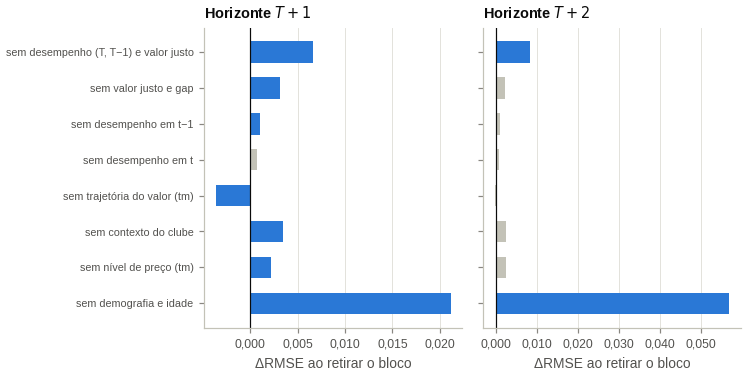

,horizonte,avaliacao,especificacao,n_variaveis,RMSE_log,R2_log,spearman,top10_hit_rate,dif_RMSE_vs_completo,dif_R2_vs_completo,dif_spearman_vs_completo,p_valor,p_holm
0,T+1,desenvolvimento,Sem demografia e idade,96,0.5403,0.1780,0.3978,0.5723,0.0211,-0.0630,-0.0757,0.0000,0.0000
1,T+1,desenvolvimento,Sem nível de preço (tm),103,0.5213,0.2346,0.4718,0.5950,0.0022,-0.0064,-0.0018,0.0001,0.0005
2,T+1,desenvolvimento,Sem contexto do clube,100,0.5226,0.2309,0.4693,0.5816,0.0034,-0.0101,-0.0042,0.0000,0.0000
3,T+1,desenvolvimento,Sem trajetória do valor (tm),98,0.5156,0.2515,0.4864,0.5837,-0.0036,0.0105,0.0128,0.0000,0.0001
4,T+1,desenvolvimento,Sem desempenho em t,50,0.5199,0.2389,0.4720,0.5785,0.0007,-0.0021,-0.0016,0.1382,0.2763
5,T+1,desenvolvimento,Sem desempenho em t−1,95,0.5202,0.2379,0.4715,0.5816,0.0011,-0.0031,-0.0020,0.0130,0.0389
6,T+1,desenvolvimento,Sem valor justo e gap,106,0.5223,0.2318,0.4677,0.5909,0.0031,-0.0092,-0.0058,0.0000,0.0000
7,T+1,desenvolvimento,"Sem desempenho (T, T−1) e valor justo",35,0.5258,0.2214,0.4489,0.5806,0.0067,-0.0196,-0.0246,0.0000,0.0000
8,T+1,desenvolvimento,M0: ciclo de vida + contexto,20,0.5375,0.1863,0.4358,0.5630,0.0184,-0.0547,-0.0377,0.0000,0.0000
9,T+1,desenvolvimento,M1: M0 + nível de preço,25,0.5239,0.2271,0.4524,0.5671,0.0047,-0.0139,-0.0211,0.0005,0.0020


In [14]:
abl_rows = []
for k in HORIZONS:
    full = ens[ens["horizon"] == k]
    scopes = {"desenvolvimento": lambda f: f[f["dev"] & f["y_true"].notna()]}
    if REVEAL_HOLDOUT:
        scopes["teste final"] = lambda f: f[f["is_holdout"] & f["y_true"].notna()]
    for scope, sel in scopes.items():
        ref = sel(full)
        ref_m = md.regression_metrics(ref)
        for name, slug in ABL_SLUG.items():
            v = variants[slug]
            v = sel(v[v["horizon"] == k])
            m = ref.merge(v[KEY + ["y_pred"]], on=KEY, suffixes=("", "_abl"))
            t = md.paired_loss_test(m["y_true"], m["y_pred_abl"], m["y_pred"], md.cluster_codes(m))
            mv = md.regression_metrics(v)
            abl_rows.append({"horizonte": f"T+{k}", "avaliacao": scope, "especificacao": name,
                             "n_variaveis": len(ABLATIONS[name][0]), "RMSE_log": mv["RMSE_log"], "R2_log": mv["R2_log"],
                             "spearman": mv["spearman"], "top10_hit_rate": mv["top10_hit_rate"],
                             "dif_RMSE_vs_completo": mv["RMSE_log"] - ref_m["RMSE_log"],
                             "dif_R2_vs_completo": mv["R2_log"] - ref_m["R2_log"],
                             "dif_spearman_vs_completo": mv["spearman"] - ref_m["spearman"], "p_valor": t["p_value"]})
        abl_rows.append({"horizonte": f"T+{k}", "avaliacao": scope, "especificacao": "Modelo completo",
                         "n_variaveis": len(NUMERIC), "RMSE_log": ref_m["RMSE_log"], "R2_log": ref_m["R2_log"],
                         "spearman": ref_m["spearman"], "top10_hit_rate": ref_m["top10_hit_rate"],
                         "dif_RMSE_vs_completo": 0.0, "dif_R2_vs_completo": 0.0, "dif_spearman_vs_completo": 0.0, "p_valor": np.nan})
ablation = pd.DataFrame(abl_rows)
ablation["p_holm"] = ablation.groupby(["horizonte", "avaliacao"])["p_valor"].transform(
    lambda s: pd.Series(md.holm(s.fillna(1.0)), index=s.index).where(s.notna()))
save_csv(ablation, "tab08_ablacao_blocos", index=False)

scope_fig = "teste final" if REVEAL_HOLDOUT else "desenvolvimento"
fig, axes = plt.subplots(1, 2, figsize=pl.figsize(9), sharey=True, gridspec_kw={"wspace": 0.08})
loco = [n for n in ABL_SLUG if n.startswith("Sem ")]
for ax, k in zip(axes, HORIZONS):
    a = ablation[(ablation["horizonte"] == f"T+{k}") & (ablation["avaliacao"] == scope_fig)].set_index("especificacao").loc[loco]
    colors_ = [pl.BLUE if p < 0.05 else pl.NEUTRAL for p in a["p_holm"]]
    ax.barh(range(len(a)), a["dif_RMSE_vs_completo"], color=colors_, height=0.6)
    ax.axvline(0, color=pl.INK, linewidth=0.8)
    ax.set_yticks(range(len(a)), [n.replace("Sem ", "sem ") for n in a.index], fontsize=7)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pl.br_formatter(3))
    ax.set_title(f"Horizonte $T+{k}$")
    ax.set_xlabel("ΔRMSE ao retirar o bloco")
    ax.grid(axis="y", visible=False)
FIG.save(fig, "fig08_ablacao_blocos",
         f"Aumento do erro ao retirar cada bloco de variáveis do ensemble ({scope_fig})",
         note="Azul: diferença significativa após a correção de Holm (p < 0,05, erro-padrão por clube × temporada).")
plt.show()
ablation.round(4)

## 8. Segmentação: 4 × 3, 3 × 3 de Khalife e modelo global (H2)

O erro de cada arquitetura é medido **dentro de cada categoria** das duas matrizes, com todas as
dobras de teste agrupadas (as de desenvolvimento e, quando revelado, o teste final). Em destaque,
os atacantes de 30 anos ou mais, a célula em que Khalife et al. (2025) relatam a maior perda de
precisão.

arquitetura                        Global — Ensemble (CatBoost + XGBoost + Ridge)  Pooling 3 × 3 — Pooling parcial  Pooling 4 × 3 — Pooling parcial  Seg. 3 × 3 — CatBoost  Seg. 3 × 3 — Ridge  Seg. 4 × 3 — CatBoost  \
horizonte particao categoria                                                                                                                                                                                            
T+1       3 × 3    K6 · ATA 24–29                                          0.5044                           0.5043                           0.5038                 0.5121              0.5185                 0.5106   
                   K9 · ATA 30+                                            0.4105                           0.4099                           0.4100                 0.4166              0.4194                 0.4168   
          4 × 3    C12 · ATA 33+                                           0.4319                           0.4311                           0.4314                 0.4344              0.4387                 0.4371   
                   C9 · ATA 29–32                                          0.4089                           0.4089                           0.4081                 0.4208              0.4269                 0.4176   
T+2       3 × 3    K6 · ATA 24–29                                          0.7329                           0.7323                           0.7320                 0.7428              0.7686                 0.7463   
                   K9 · ATA 30+                                            0.5839                           0.5827                           0.5811                 0.5951              0.5926                 0.5874   
          4 × 3    C12 · ATA 33+                                           0.6027                           0.5985                           0.5996                 0.6044              0.5939                 0.5901   
                   C9 · ATA 29–32                                          0.5826                           0.5834                           0.5796                 0.6029              0.6144                 0.6026   

arquitetura                        Seg. 4 × 3 — Ridge  
horizonte particao categoria                           
T+1       3 × 3    K6 · ATA 24–29              0.5164  
                   K9 · ATA 30+                0.4216  
          4 × 3    C12 · ATA 33+               0.4406  
                   C9 · ATA 29–32              0.4214  
T+2       3 × 3    K6 · ATA 24–29              0.7664  
                   K9 · ATA 30+                0.5885  
          4 × 3    C12 · ATA 33+               0.5915  
                   C9 · ATA 29–32              0.5987

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig03_r2_por_categoria.png


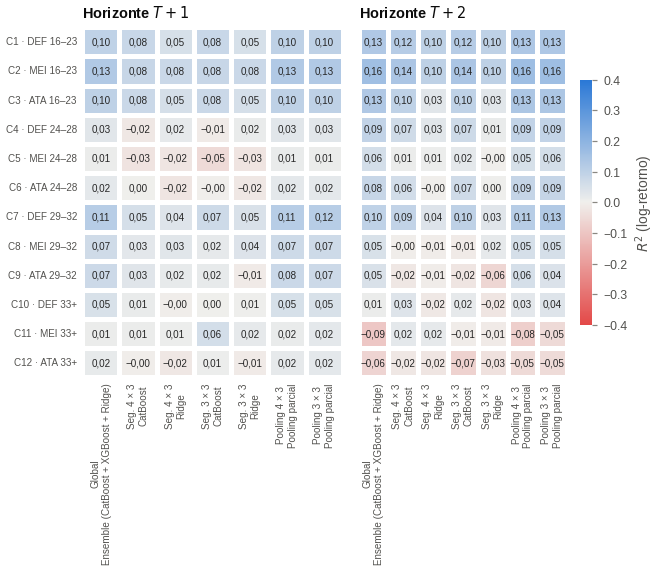

In [15]:
lookup = panel[["season", "fbref_player_id", "category", "category_3x3"]].rename(columns={"category": "cat4"})
seg_rows = []
for k in HORIZONS:
    for approach, model in ARCHS:
        f = arch_frame(k, approach, model)
        f = f[f["y_true"].notna() & (f["dev"] | (f["is_holdout"] & REVEAL_HOLDOUT))].merge(lookup, on=["season", "fbref_player_id"])
        for col, labels in (("cat4", sp.category_labels()), ("category_3x3", SEGMENTATIONS["3x3"][2])):
            for c, g in f.groupby(col):
                m = md.regression_metrics(g)
                seg_rows.append({"horizonte": f"T+{k}", "particao": "4 × 3" if col == "cat4" else "3 × 3",
                                 "categoria": labels[c], "arquitetura": f"{approach} — {LABELS[model]}",
                                 "n": int(m["n"]), "RMSE_log": m["RMSE_log"], "R2_log": m["R2_log"], "spearman": m["spearman"]})
seg_metrics = pd.DataFrame(seg_rows)
save_csv(seg_metrics, "tab09_metricas_por_categoria", index=False)

h2 = seg_metrics[seg_metrics["categoria"].str.contains("ATA") & seg_metrics["categoria"].str.contains("29|30|33")]
h2_tab = h2.pivot_table(index=["horizonte", "particao", "categoria"], columns="arquitetura", values="RMSE_log")
save_csv(h2_tab, "tab09b_h2_atacantes_veteranos")
display(h2_tab.round(4))

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(10.5), sharey=True, gridspec_kw={"wspace": 0.06})
arch_names = [f"{a} — {LABELS[m]}" for a, m in ARCHS]
for ax, k in zip(axes, HORIZONS):
    d = (seg_metrics[(seg_metrics["horizonte"] == f"T+{k}") & (seg_metrics["particao"] == "4 × 3")]
         .pivot(index="categoria", columns="arquitetura", values="R2_log").reindex(columns=arch_names))
    d = d.reindex(list(sp.category_labels().values()))
    d.columns = [c.replace(" — ", "\n") for c in d.columns]
    sns.heatmap(d, annot=pl.annotations(d, 2), fmt="", cmap=pl.DIVERGING, center=0, vmin=-0.4, vmax=0.4,
                linewidths=2, linecolor=pl.SURFACE, cbar=ax is axes[1], ax=ax, annot_kws={"fontsize": 6.5},
                cbar_kws={"label": "$R^2$ (log-retorno)", "shrink": 0.7})
    ax.set_title(f"Horizonte $T+{k}$")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(length=0, labelsize=6.5)
    ax.grid(False)
FIG.save(fig, "fig03_r2_por_categoria",
         "R² do log-retorno por categoria (matriz 4 × 3) e arquitetura",
         note="Todas as dobras de teste agrupadas. Global: ensemble com faixa etária e posição como variáveis; "
              "Pooling: segmento encolhido para o global.")
plt.show()

## 9. Estabilidade temporal e calibração do modelo final

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig04_estabilidade_temporal.png


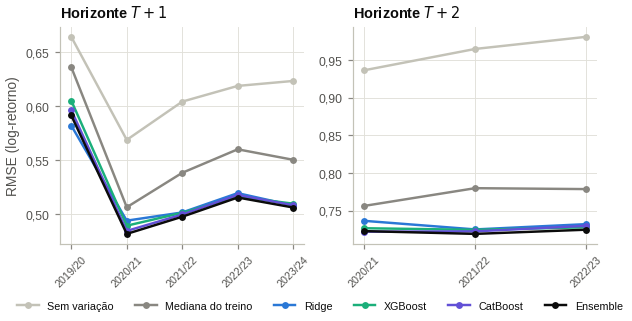

In [16]:
def final_predictions(k: int) -> pd.DataFrame:
    return arch_frame(k, decisions[k]["approach"], decisions[k]["model"])


visible = lambda f: f[f["dev"] | (f["is_holdout"] & REVEAL_HOLDOUT)]  # noqa: E731

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), sharey=False, gridspec_kw={"wspace": 0.2})
line_colors = {"zero": pl.NEUTRAL, "median": pl.INK_MUTED, "ridge": pl.BLUE, "xgb": pl.AQUA, "cat": "#6250d6", "ens": pl.INK}
stab_rows = []
for ax, k in zip(axes, HORIZONS):
    for m, color in line_colors.items():
        f = visible(arch_frame(k, "Global", m))
        s = f[f["y_true"].notna()].groupby("season").apply(lambda d: md.rmse(d["y_true"], d["y_pred"]))
        stab_rows += [{"horizonte": f"T+{k}", "modelo": LABELS[m], "temporada": sp.season_label(t), "RMSE_log": v} for t, v in s.items()]
        ax.plot(range(len(s)), s.to_numpy(), color=color, marker="o", markersize=3.5, linewidth=1.6, label=LABELS[m].split(" (")[0])
    ax.set_xticks(range(len(s)), [sp.season_label(t) for t in s.index], rotation=45, fontsize=7)
    ax.set_title(f"Horizonte $T+{k}$")
    ax.yaxis.set_major_formatter(pl.br_formatter(2))
axes[0].set_ylabel("RMSE (log-retorno)")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=6, fontsize=7)
save_csv(pd.DataFrame(stab_rows), "tab10_rmse_por_temporada", index=False)
FIG.save(fig, "fig04_estabilidade_temporal", "RMSE do log-retorno por temporada de teste nos modelos globais",
         note="Dobras de desenvolvimento" + (" e teste final." if REVEAL_HOLDOUT else "; teste final oculto."))
plt.show()

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig05_calibracao_decis.png


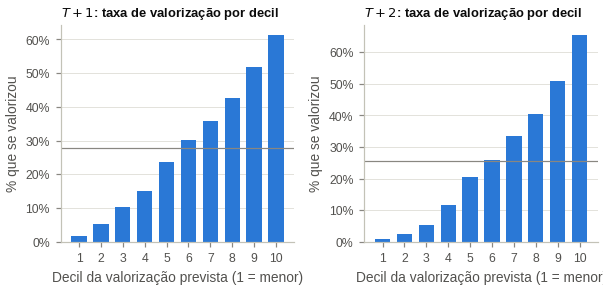

,mediana_dv_pct,pct_valorizou,previsto_mediano_pct,horizonte
decil,,,,
1,-42.5000,1.8000,-44.1000,T+1
2,-37.5000,5.2000,-38.5000,T+1
3,-31.4000,10.1000,-33.3000,T+1
4,-25.0000,15.1000,-27.6000,T+1
5,-18.8000,23.6000,-21.7000,T+1
6,-16.7000,30.1000,-15.8000,T+1
7,-6.7000,35.7000,-9.2000,T+1
8,0.0000,42.6000,-1.0000,T+1
9,10.0000,51.7000,8.7000,T+1


In [17]:
fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), gridspec_kw={"wspace": 0.3})
dec_rows = []
for ax, k in zip(axes, HORIZONS):
    p = visible(final_predictions(k))
    p = p[p["y_true"].notna()]
    p = p.assign(decil=p.groupby("season")["y_pred"].transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1))
    dec = p.groupby("decil").agg(mediana_dv_pct=("dv_pct_true", "median"), pct_valorizou=("y_true", lambda s: (s > 0).mean() * 100),
                                 previsto_mediano_pct=("y_pred", lambda s: np.expm1(s.median()) * 100))
    dec_rows.append(dec.assign(horizonte=f"T+{k}"))
    ax.bar(dec.index, dec["pct_valorizou"], color=pl.BLUE, width=0.7)
    ax.axhline((p["y_true"] > 0).mean() * 100, color=pl.INK_MUTED, linewidth=0.8)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("Decil da valorização prevista (1 = menor)")
    ax.set_ylabel("% que se valorizou")
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_title(f"$T+{k}$: taxa de valorização por decil", fontsize=8.5)
    ax.grid(axis="x", visible=False)
save_csv(pd.concat(dec_rows), "tab11_decis_valorizacao_prevista")
FIG.save(fig, "fig05_calibracao_decis", "Taxa de valorização observada por decil de valorização prevista (modelo final)",
         note="Decis calculados dentro de cada temporada de teste. A linha horizontal é a taxa média.")
plt.show()
pd.concat(dec_rows).round(1)

## 10. Camada de magnitude

Recalibração linear $\hat y' = a + b\hat y$ e *smearing* de Duan (1983) por faixa etária, estimados
**só com as dobras anteriores**. Ela produz a **mediana** $e^{\hat y'}-1$ e a **esperança**
$f_g e^{\hat y'}-1$ da variação.

**Diferença em relação à versão 2, decidida nas dobras de desenvolvimento:** a 1ª dobra fica fora do
histórico (`modeling.calibration_history`). Ela treina com uma temporada só (2018/19, cujo alvo de
$T+1$ é a revisão de abril de 2020): o regime de mercado é constante no treino, e o nível da previsão
não é identificável. Seu erro de nível é estrutural (inclinação de $y$ sobre $\hat y$ de 2,06 e
intercepto de +0,54 dentro da dobra) e, no histórico, deslocava a recalibração das dobras seguintes
para cima (+0,09 em log nas dobras 3 a 5 de $T+1$) e inflava o *smearing* e o ajuste conformal. A
camada passa a valer a partir da 3ª dobra; na 2ª, ainda sem histórico, é a identidade. A comparação com a versão 2 usa a temporada 2023/24, a
única avaliada pelas duas versões (na v3 ela é dobra de desenvolvimento em $T+1$ e teste final em $T+2$).

In [18]:
AGE_OF_CAT = {f"C{b * 3 + p + 1}": band for b, band in enumerate(sp.AGE_BAND_LABELS) for p in range(3)}
magnitude = {k: md.magnitude_layer(final_predictions(k).assign(age_band=lambda d: d["category"].map(AGE_OF_CAT)))
             for k in HORIZONS}
v2 = pd.read_parquet(paths.reports / "archive" / "v2_2026-10-19" / "predictions_best_v2.parquet")
mag_cols = ["n", "RMSE_log", "R2_log", "spearman", "calib_slope", "MAE_pct", "MedAE_pct", "R2_pct", "MAE_pct_valorizados",
            "R2_eur", "top10_hit_rate"]
rows = []
for k in HORIZONS:
    if HOLDOUT[k] == "2324" and not REVEAL_HOLDOUT:   # em T+2, 2023/24 é o teste final da v3
        continue
    m3 = magnitude[k][magnitude[k]["season"] == "2324"].assign(y_pred=lambda d: d["y_pred_cal"])
    m2 = v2[(v2["horizon"] == k) & (v2["season"] == "2324")].assign(y_pred=lambda d: d["y_pred_cal"])
    common = m3.merge(m2[["fbref_player_id"]], on="fbref_player_id")
    m2c = m2.merge(m3[["fbref_player_id"]], on="fbref_player_id")
    for name, frame, col in (("v2 (2023/24): esperança", m2c, "dv_pct_pred_mean"), ("v3 (2023/24): esperança", common, "dv_pct_pred_mean"),
                             ("v3 (2023/24): mediana", common, "dv_pct_pred_median")):
        rows.append(md.regression_metrics(frame, col)[mag_cols].rename((f"T+{k}", name)))
    if REVEAL_HOLDOUT:
        hold = magnitude[k][magnitude[k]["is_holdout"]].assign(y_pred=lambda d: d["y_pred_cal"])
        rows.append(md.regression_metrics(hold, "dv_pct_pred_mean")[mag_cols].rename((f"T+{k}", f"v3 teste final ({sp.season_label(HOLDOUT[k])}): esperança")))
mag_tab = pd.DataFrame(rows)
mag_tab.index = pd.MultiIndex.from_tuples(mag_tab.index, names=["horizonte", "versao"])
save_csv(mag_tab, "tab12_magnitude_v2_v3")
display(mag_tab.round(3))
smear = pd.DataFrame({f"T+{k}": magnitude[k][magnitude[k]["fold"] == N_FOLDS[k]].groupby("age_band")["smearing"].first()
                      for k in HORIZONS})
display(smear.round(3).rename_axis("fator de smearing (última dobra)"))

n  RMSE_log  R2_log  spearman  calib_slope  MAE_pct  MedAE_pct  R2_pct  MAE_pct_valorizados  R2_eur  top10_hit_rate
horizonte versao                                                                                                                                              
T+1       v2 (2023/24): esperança 1,912.0000    0.5130  0.2700    0.5060       1.3250  48.4630    26.8080  0.1510             101.6160  0.1770          0.5290
          v3 (2023/24): esperança 1,912.0000    0.5070  0.2900    0.5110       1.1390  49.1010    27.0520  0.1870              97.6880  0.1700          0.5450
          v3 (2023/24): mediana   1,912.0000    0.5070  0.2900    0.5110       1.1390  46.0700    23.4170  0.1370             113.9790  0.2000          0.5450

,T+1,T+2
fator de smearing (última dobra),,
16–23,1.3120,1.5850
24–28,1.1230,1.2240
29–32,1.0700,1.2110
33+,1.0390,1.1640


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig06_magnitude_decis.png


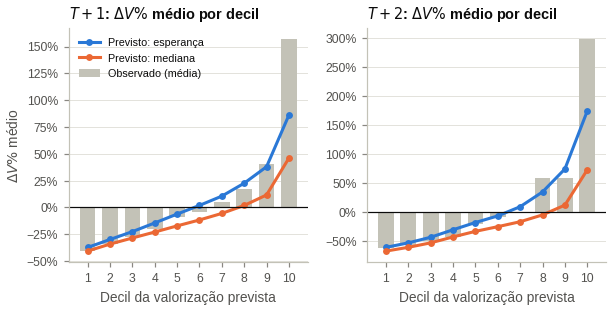

In [19]:
fig, axes = plt.subplots(1, 2, figsize=pl.figsize(7), gridspec_kw={"wspace": 0.25})
dec_mag = []
for ax, k in zip(axes, HORIZONS):
    m = visible(magnitude[k])
    m = m[(m["fold"] >= FIRST_CAL) & m["y_true"].notna()].copy()
    m["decil"] = m.groupby("season")["y_pred_cal"].transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
    d = m.groupby("decil").agg(observado=("dv_pct_true", "mean"), esperanca=("dv_pct_pred_mean", "mean"),
                               mediana=("dv_pct_pred_median", "mean"))
    dec_mag.append(d.assign(horizonte=f"T+{k}"))
    ax.bar(d.index, d["observado"], color=pl.NEUTRAL, width=0.7, label="Observado (média)")
    ax.plot(d.index, d["esperanca"], color=pl.BLUE, marker="o", markersize=3.5, label="Previsto: esperança")
    ax.plot(d.index, d["mediana"], color=pl.ORANGE, marker="o", markersize=3.5, label="Previsto: mediana")
    ax.axhline(0, color=pl.INK, linewidth=0.8)
    ax.set_xticks(range(1, 11))
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_xlabel("Decil da valorização prevista")
    ax.set_title(f"$T+{k}$: $\\Delta V\\%$ médio por decil")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("$\\Delta V\\%$ médio")
axes[0].legend(loc="upper left", fontsize=7)
save_csv(pd.concat(dec_mag), "tab12b_magnitude_por_decil")
FIG.save(fig, "fig06_magnitude_decis", "Variação percentual média observada e prevista por decil de valorização prevista",
         note=f"Dobras de teste a partir da {FIRST_CAL}ª (a camada usa só dobras anteriores, sem a de aquecimento).")
plt.show()

## 11. Intervalos de previsão (P10–P90)

Quantis do CatBoost com os hiperparâmetros do modelo principal, conformalizados sequencialmente com
as dobras anteriores, com o mesmo histórico da camada de magnitude (Romano, Patterson e Candès,
2019).

n  cobertura  cobertura_nominal  largura_mediana_pp  abaixo_do_inferior  acima_do_superior  pinball_q10  pinball_q90
horizonte intervalo      avaliacao                                                                                                                                                  
T+1       bruto          dobras de desenvolvimento ≥ 3 5,831.0000     0.7780             0.8000             95.1290              0.1130             0.1080       0.0830       0.0940
          conformalizado dobras de desenvolvimento ≥ 3 5,831.0000     0.8160             0.8000            106.7760              0.0930             0.0910       0.0830       0.0940
T+2       bruto          dobras de desenvolvimento ≥ 3 1,905.0000     0.7930             0.8000            128.3020              0.1070             0.1000       0.1260       0.1300
          conformalizado dobras de desenvolvimento ≥ 3 1,905.0000     0.8340             0.8000            147.7260              0.0850             0.0810       0.1260       0.1310

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig07_intervalos_previsao.png


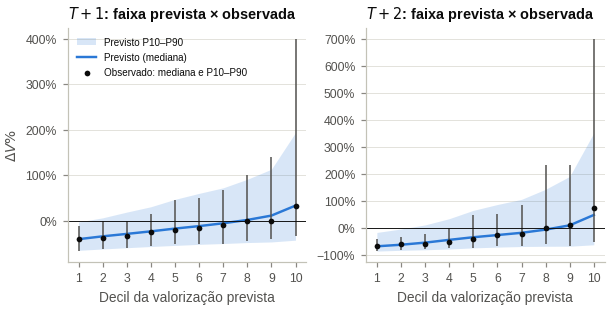

In [20]:
quant = [r for r in fixed_results if r["task"].extra_label in ("q10", "q90")]
qpred = pd.concat([r["predictions"].assign(horizon=r["task"].horizon, q=r["task"].extra_label) for r in quant])
qwide = qpred.pivot_table(index=["horizon", "season", "fbref_player_id"], columns="q", values="y_pred").reset_index()
intervals, int_rows = {}, []
for k in HORIZONS:
    m = magnitude[k].merge(qwide[qwide["horizon"] == k].drop(columns="horizon"), on=["season", "fbref_player_id"])
    m["q10"], m["q90"] = np.minimum(m["q10"], m["y_pred_cal"]), np.maximum(m["q90"], m["y_pred_cal"])
    m = md.conformal_interval(m, "q10", "q90", 0.8)
    intervals[k] = m.assign(horizon=k)
    scopes = {f"dobras de desenvolvimento ≥ {FIRST_CAL}": m[m["dev"] & (m["fold"] >= FIRST_CAL)]}
    if REVEAL_HOLDOUT:
        scopes["teste final"] = m[m["is_holdout"]]
    for name, lo, hi in (("bruto", "q10", "q90"), ("conformalizado", "q10_conf", "q90_conf")):
        for scope, frame in scopes.items():
            int_rows.append(md.interval_metrics(frame, lo, hi).rename((f"T+{k}", name, scope)))
int_tab = pd.DataFrame(int_rows)
int_tab.index = pd.MultiIndex.from_tuples(int_tab.index, names=["horizonte", "intervalo", "avaliacao"])
save_csv(int_tab, "tab13_intervalos_previsao")
display(int_tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(7), sharey=False, gridspec_kw={"wspace": 0.25})
for ax, k in zip(axes, HORIZONS):
    m = visible(intervals[k])
    m = m[(m["fold"] >= FIRST_CAL) & m["y_true"].notna()].copy()
    m["decil"] = m.groupby("season")["y_pred_cal"].transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
    g = m.groupby("decil")
    obs = g["dv_pct_true"].quantile([0.1, 0.5, 0.9]).unstack()
    x = obs.index.to_numpy()
    ax.fill_between(x, g["q10_conf"].median().pipe(np.expm1) * 100, g["q90_conf"].median().pipe(np.expm1) * 100,
                    color=pl.BLUE, alpha=0.18, linewidth=0, label="Previsto P10–P90")
    ax.plot(x, g["y_pred_cal"].median().pipe(np.expm1) * 100, color=pl.BLUE, linewidth=1.6, label="Previsto (mediana)")
    ax.vlines(x, obs[0.1], obs[0.9], color=pl.INK_SECONDARY, linewidth=1)
    ax.scatter(x, obs[0.5], color=pl.INK, s=14, zorder=3, label="Observado: mediana e P10–P90")
    ax.axhline(0, color=pl.INK, linewidth=0.6)
    ax.set_xticks(range(1, 11))
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_xlabel("Decil da valorização prevista")
    ax.set_title(f"$T+{k}$: faixa prevista × observada")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("$\\Delta V\\%$")
axes[0].legend(loc="upper left", fontsize=6.5)
FIG.save(fig, "fig07_intervalos_previsao",
         "Intervalo de previsão de 80% (P10–P90) e distribuição observada da variação percentual por decil",
         note=f"Quantis do CatBoost conformalizados com as dobras anteriores; dobras de teste a partir da {FIRST_CAL}ª.")
plt.show()

## 12. Robustez

Variações do *ensemble* com os mesmos hiperparâmetros, exceto na primeira linha:
- **hiperparâmetros-padrão**, sem otimização: mede quanto a otimização "aprendeu" as dobras de
  validação em que foi feita;
- **taxas cruas**, sem o encolhimento empírico-bayesiano;
- **sem 2018/19 no treino**: retira as janelas de alvo que cruzam a revisão extraordinária de abril de
  2020;
- **contrato reconstruído** (*look-ahead*): limite superior contaminado, só no XGBoost, como na versão 2.

In [21]:
rob_rows = []
for k in HORIZONS:
    scopes = {"desenvolvimento": lambda f: f[f["dev"] & f["y_true"].notna()]}
    if REVEAL_HOLDOUT:
        scopes["teste final"] = lambda f: f[f["is_holdout"] & f["y_true"].notna()]
    for scope, sel in scopes.items():
        ref = sel(ens[ens["horizon"] == k])
        named = {"Ensemble principal": ref}
        named |= {label: sel(variants[x][variants[x]["horizon"] == k]) for x, label in
                  (("padrao", "Hiperparâmetros-padrão"), ("cru", "Taxas cruas (sem encolhimento)"), ("sem_pandemia", "Sem 2018/19 no treino"))}
        named["XGBoost principal"] = sel(arch_frame(k, "Global", "xgb"))
        la = pred[(pred["extra"] == "lookahead") & (pred["horizon"] == k)]
        named["XGBoost + contrato reconstruído (look-ahead)"] = sel(la)
        for label, f in named.items():
            common = ref.merge(f[KEY + ["y_pred"]], on=KEY, suffixes=("_ref", ""))
            m = md.regression_metrics(common.drop(columns="y_pred_ref"))
            t = md.paired_loss_test(common["y_true"], common["y_pred"], common["y_pred_ref"], md.cluster_codes(common))
            rob_rows.append({"horizonte": f"T+{k}", "avaliacao": scope, "especificacao": label, "n": int(m["n"]),
                             "RMSE_log": m["RMSE_log"], "R2_log": m["R2_log"], "spearman": m["spearman"],
                             "top10_hit_rate": m["top10_hit_rate"], "p_vs_ensemble": t["p_value"] if label != "Ensemble principal" else np.nan})
robust = pd.DataFrame(rob_rows)
save_csv(robust, "tab14_robustez", index=False)
robust.round(4)

,horizonte,avaliacao,especificacao,n,RMSE_log,R2_log,spearman,top10_hit_rate,p_vs_ensemble
0,T+1,desenvolvimento,Ensemble principal,9682,0.5192,0.2410,0.4735,0.5857,NaN
1,T+1,desenvolvimento,Hiperparâmetros-padrão,9682,0.5148,0.2537,0.4850,0.5981,0.0000
2,T+1,desenvolvimento,Taxas cruas (sem encolhimento),9682,0.5201,0.2384,0.4719,0.5930,0.0050
3,T+1,desenvolvimento,Sem 2018/19 no treino,7798,0.5178,0.2042,0.4656,0.5379,0.0000
4,T+1,desenvolvimento,XGBoost principal,9682,0.5252,0.2232,0.4521,0.5837,0.0000
5,T+1,desenvolvimento,XGBoost + contrato reconstruído (look-ahead),9682,0.5207,0.2366,0.4693,0.5919,0.1072
6,T+2,desenvolvimento,Ensemble principal,5709,0.7222,0.3212,0.5502,0.6526,NaN
7,T+2,desenvolvimento,Hiperparâmetros-padrão,5709,0.7220,0.3216,0.5499,0.6491,0.8631
8,T+2,desenvolvimento,Taxas cruas (sem encolhimento),5709,0.7224,0.3208,0.5500,0.6579,0.6364
9,T+2,desenvolvimento,Sem 2018/19 no treino,3819,0.7356,0.3236,0.5616,0.6614,0.0000


## 13. Modelos finais e gravação

In [22]:
FINAL.mkdir(parents=True, exist_ok=True)
manifest = {"created": pd.Timestamp.now().isoformat(timespec="seconds"), "target": "log-retorno ln(V_{T+k}/V_T)",
            "numeric_features": list(NUMERIC), "data_tag": DATA_TAG, "protocol": str(PROTOCOL_PATH.name),
            "holdout_revealed": REVEAL_HOLDOUT, "horizons": {}}
for k in HORIZONS:
    entry = {"approach": decisions[k]["approach"], "model": decisions[k]["model"], "global": {},
             "folds": [{"train": list(f.train), "test": f.test} for f in folds[k]]}
    for m in ENSEMBLE:
        task = T(k, "global", m)
        model = md.fit_final(SPECS["global"][m], P(k, m), task, panel)
        path = FINAL / f"T{k}" / f"global_{m}.joblib"
        path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump({"model": model, "task": task, "params": P(k, m)}, path)
        entry["global"][m] = {"model": m, "label": MODEL_LABELS[m], "params": P(k, m), "path": str(path.relative_to(paths.root)),
                              "categorical": list(task.categorical), "numeric": list(task.numeric),
                              "n_trees": getattr(model, "n_trees_", None), "n_train": int(md.task_data(panel, task).shape[0])}
    for q in (0.1, 0.9):
        qt = T(k, "global", "cat", extra=f"q{int(q * 100)}")
        fixed = P(k, "cat") | {"loss_function": f"Quantile:alpha={q}"}
        qm = md.fit_final(SPECS["global"]["cat"], fixed, qt, panel)
        qpath = FINAL / f"T{k}" / f"global_cat_q{int(q * 100)}.joblib"
        joblib.dump({"model": qm, "task": qt, "params": fixed}, qpath)
        entry[f"q{int(q * 100)}"] = {"path": str(qpath.relative_to(paths.root)), "params": fixed}
    if decisions[k]["approach"] != "Global":  # segmentos do pooling ou da arquitetura segmentada vencedora
        col = "category" if "4 × 3" in decisions[k]["approach"] else "category_3x3"
        seg_model = "cat" if decisions[k]["model"] == "pool" else decisions[k]["model"]
        kappa = best_kappa[(col, k)] if decisions[k]["model"] == "pool" else 0.0
        by_scope = {}
        for c in SEGMENTATIONS["4x3" if col == "category" else "3x3"][1]:
            st = T(k, c, seg_model, scope_col=col)
            pc = by_key[(k, c, seg_model)]["params"]
            sm = md.fit_final(SPECS["segment"][seg_model], pc, st, panel)
            spath = FINAL / f"T{k}" / f"segment_{c}_{seg_model}.joblib"
            joblib.dump({"model": sm, "task": st, "params": pc}, spath)
            by_scope[c] = {"path": str(spath.relative_to(paths.root)), "n_train": int(md.task_data(panel, st).shape[0]),
                           "params": pc}
        entry["segments"] = {"scope_col": col, "model": seg_model, "kappa": kappa, "by_scope": by_scope}
    m = md.calibration_history(visible(magnitude[k]), N_FOLDS[k] + 1)
    b, a = np.polyfit(m["y_pred"], m["y_true"], 1)
    ratio = np.exp(m["y_true"] - (a + b * m["y_pred"]))
    entry["magnitude_layer"] = {"a": float(a), "b": float(b), "smearing_by_age_band": ratio.groupby(m["age_band"]).mean().round(4).to_dict(),
                                "conformal_adj": float(intervals[k]["conformal_adj"].iloc[-1])}
    manifest["horizons"][f"T{k}"] = entry
(FINAL / "manifest.json").write_text(json.dumps(jsonable(manifest), ensure_ascii=False, indent=2, default=str), encoding="utf-8")

meta_cols = ["season", "fbref_player_id", "fb_player", "fb_team", "league", "age_band", "position_group", "category_3x3"]
# as previsões da ablação ficam só no cache (dezenas de variantes); o arquivo guarda as principais e a robustez
oof = pred[~pred["extra"].str.startswith("abl")].merge(panel[meta_cols], on=["season", "fbref_player_id"], how="left")
oof["dv_pct_pred"] = np.expm1(oof["y_pred"]) * 100
if not REVEAL_HOLDOUT:  # o teste final só sai do notebook depois do protocolo
    oof = oof[~oof["is_holdout"]].copy()
save_table(oof, PROCESSED_OUT / "predictions_oof.parquet",
           source="notebook 04: previsões fora da amostra (janela expandida) de todos os modelos e variantes")
best = pd.concat([intervals[k] for k in HORIZONS])
# previsão do componente global (o ensemble que o SHAP do notebook 05 explica), ao lado da previsão final
best = best.merge(ens[KEY + ["y_pred"]].rename(columns={"y_pred": "y_pred_global"}), on=KEY, how="left")
best = best.merge(panel[[c for c in meta_cols if c not in ("age_band",)] + ["value_T1_last_obs", "value_T2_last_obs"]],
                  on=["season", "fbref_player_id"], how="left")
best["value_last_obs"] = np.where(best["horizon"] == 1, best["value_T1_last_obs"], best["value_T2_last_obs"])
best["dv_pct_pred"] = best["dv_pct_pred_median"]
if not REVEAL_HOLDOUT:  # o teste final só sai do notebook depois do protocolo
    best = best[~best["is_holdout"]].copy()
save_table(best, PROCESSED_OUT / "predictions_best.parquet",
           source="notebook 04: previsões fora da amostra da arquitetura final (inclui atletas sem V_{T+k})")
FIG.write_index()
print(json.dumps({k: {"arquitetura": f"{v['approach']} — {LABELS[v['model']]}",
                      "arvores": {m: e["n_trees"] for m, e in v["global"].items()}} for k, v in
                  {k: manifest["horizons"][f"T{k}"] | decisions[k] for k in HORIZONS}.items()}, ensure_ascii=False, indent=1))

I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/predictions_oof.parquet rows=369459 cols=26


I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/predictions_best.parquet rows=15885 cols=39


{
 "1": {
  "arquitetura": "Global — Ensemble (CatBoost + XGBoost + Ridge)",
  "arvores": {
   "cat": 714,
   "xgb": 479,
   "ridge": null
  }
 },
 "2": {
  "arquitetura": "Pooling 3 × 3 — Pooling parcial",
  "arvores": {
   "cat": 246,
   "xgb": 299,
   "ridge": null
  }
 }
}


## 14. Síntese para o artigo

A síntese é escrita depois da execução com o teste revelado, a partir das tabelas `tab05` (teste
final), `tab06` (testes pareados e MCS), `tab08` (ablação), `tab09` (segmentação) e `tab14` (robustez).